# AIOps track: monitoring a model in production

You publish model-health metrics, chart drift, alarm on it, and search scoring logs.

**You will practise:** CloudWatch custom metrics, statistics, alarms and alarm history, and CloudWatch Logs filtering. These calls work unchanged against real AWS.

In [1]:
import sys, json, time, datetime as dt
sys.path.insert(0, "../..")          # repository root: emu.py, lab_common.py
import pandas as pd
import matplotlib.pyplot as plt
import emu
from lab_common import *

df = ensure_lake()                   # buckets, loan book in S3, Glue table (safe to re-run)
print("Connected to", emu.settings()["endpoint_url"], "-", len(df), "loans in the lake")

Connected to https://127.0.0.1:9297 - 2000 loans in the lake


## 1. Publish a metric history

Simulate twelve five-minute readings of model AUC that drift downwards, as happens when the customer mix changes.

In [2]:
import numpy as np
cw = emu.client("cloudwatch")
NS, DIMS = "Lending/ModelHealth", [{"Name": "Model", "Value": "default-model"}]
now = dt.datetime.now(dt.timezone.utc).replace(second=0, microsecond=0)
_, auc, _, _ = train_default_model(df)
rng = np.random.default_rng(3)
series = [(now - dt.timedelta(minutes=5 * (11 - i)), auc - 0.012 * i + rng.normal(0, 0.004)) for i in range(12)]

attempt("PutMetricData", lambda: cw.put_metric_data(Namespace=NS, MetricData=[
    {"MetricName": "AUC", "Dimensions": DIMS, "Timestamp": t, "Value": float(v), "Unit": "None"} for t, v in series]))
print(f"Published 12 readings from {series[0][1]:.3f} down to {series[-1][1]:.3f}")

OK      PutMetricData
Published 12 readings from 0.798 down to 0.656


## 2. Read the statistics back and chart the drift

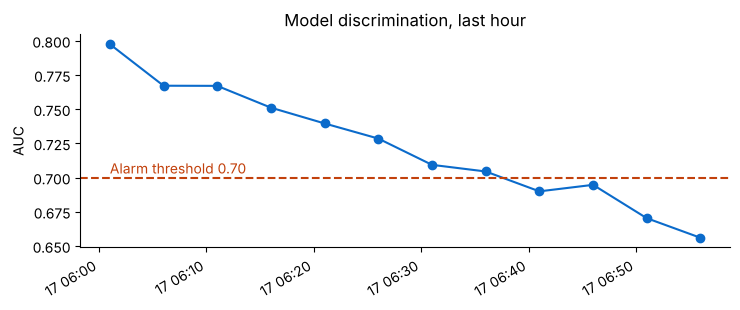

In [3]:
points = cw.get_metric_statistics(Namespace=NS, MetricName="AUC", Dimensions=DIMS, Period=300, Statistics=["Average"],
    StartTime=now - dt.timedelta(hours=2), EndTime=now + dt.timedelta(minutes=5))["Datapoints"]
ts = pd.DataFrame(points).sort_values("Timestamp")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(ts["Timestamp"], ts["Average"], marker="o", color="#0b6bcb")
ax.axhline(0.70, color="#c2410c", linestyle="--"); ax.text(ts["Timestamp"].iloc[0], 0.703, "Alarm threshold 0.70", color="#c2410c")
ax.set_ylabel("AUC"); ax.set_title("Model discrimination, last hour"); ax.spines[["top", "right"]].set_visible(False)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 3. Alarm on model quality

The alarm fires when average AUC over five minutes falls below 0.70.

In [4]:
attempt("PutMetricAlarm", lambda: cw.put_metric_alarm(
    AlarmName="default-model-auc-low", Namespace=NS, MetricName="AUC", Dimensions=DIMS,
    Statistic="Average", Period=300, EvaluationPeriods=1, Threshold=0.70, ComparisonOperator="LessThanThreshold",
    AlarmDescription="Model discrimination has fallen below the 0.70 gate", TreatMissingData="notBreaching"))
time.sleep(3)
a = cw.describe_alarms(AlarmNames=["default-model-auc-low"])["MetricAlarms"][0]
print("State :", a["StateValue"]); print("Reason:", a.get("StateReason"))

OK      PutMetricAlarm


State : ALARM
Reason: Threshold Crossed: 1 out of the last 1 datapoints [0.6559754417349143 (17/11/26 06:52:00)] was less than the threshold (0.7) (minimum 1 datapoint for OK -> ALARM transition).


### Incident drill

Force the alarm state to rehearse the response, then read the alarm history as an audit trail.

In [5]:
attempt("SetAlarmState", lambda: cw.set_alarm_state(AlarmName="default-model-auc-low", StateValue="ALARM", StateReason="Incident drill"))
history = cw.describe_alarm_history(AlarmName="default-model-auc-low")["AlarmHistoryItems"]
pd.DataFrame([{"time": h["Timestamp"], "type": h["HistoryItemType"], "summary": h["HistorySummary"]} for h in history])

OK      SetAlarmState


,time,type,summary
0,2026-11-17 06:56:56.013000+00:00,StateUpdate,Alarm updated from INSUFFICIENT_DATA to ALARM
1,2026-11-17 06:56:55.512000+00:00,ConfigurationUpdate,"Alarm ""default-model-auc-low"" created"


## 4. Scoring logs: write and search

A scoring service logs every decision. Filter for errors, the first step of most incident investigations.

In [6]:
logs = emu.client("logs")
GROUP, STREAM = "/lending/scoring-service", "instance-1"
if GROUP not in [g["logGroupName"] for g in logs.describe_log_groups()["logGroups"]]:
    logs.create_log_group(logGroupName=GROUP); logs.create_log_stream(logGroupName=GROUP, logStreamName=STREAM)
base = int(time.time() * 1000)
lines = [f"INFO scored {r.loan_id} pd=0.{r.credit_score % 90:02d} latency_ms={40 + r.credit_score % 30}" for r in df.head(30).itertuples()]
lines[7] = "ERROR feature store timeout loan_id=LN100007 latency_ms=3000"
lines[19] = "ERROR model artefact checksum mismatch"
attempt("PutLogEvents", lambda: logs.put_log_events(logGroupName=GROUP, logStreamName=STREAM,
    logEvents=[{"timestamp": base + i, "message": m} for i, m in enumerate(lines)]))
errors = logs.filter_log_events(logGroupName=GROUP, filterPattern="ERROR")["events"]
pd.DataFrame([{"time": pd.to_datetime(e["timestamp"], unit="ms"), "message": e["message"]} for e in errors])

OK      PutLogEvents


,time,message
0,2026-11-17 06:56:58.634,ERROR feature store timeout loan_id=LN100007 l...
1,2026-11-17 06:56:58.646,ERROR model artefact checksum mismatch


## Exercises

1. Publish a `DefaultRate` metric and add a second alarm on it.
2. Add an SNS topic as the alarm action and confirm it appears in `describe_alarms`.
3. Parse `latency_ms` from the log lines and publish the 95th percentile as a metric.